In [2]:
import torch
import itertools
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def hopfield_retrieve(
    initial_state,
    W,
    max_sweeps=20,
    tol=1e-12
):
    s = initial_state.clone()

    for _ in range(max_sweeps):
        changed = False

        for i in range(len(s)):

            field = torch.dot(
                W[i],
                s
            ).item()

            if field > tol:
                new_value = 1.0

            elif field < -tol:
                new_value = -1.0

            else:
                # tie -> stato precedente
                new_value = s[i].item()

            if new_value != s[i].item():
                s[i] = new_value
                changed = True

        if not changed:
            break

    return s

In [4]:
def random_patterns(
    N,
    M,
    seed
):
    g = torch.Generator()
    g.manual_seed(seed)

    patterns = []

    while len(patterns) < M:

        p = (
            torch.randint(
                0,
                2,
                (N,),
                generator=g
            ).float()
            * 2
            - 1
        )

        valid = True

        for old in patterns:

            if (
                torch.equal(p, old)
                or
                torch.equal(p, -old)
            ):
                valid = False
                break

        if valid:
            patterns.append(p)

    return torch.stack(patterns)

In [5]:
def hebbian_weights(patterns):

    M, N = patterns.shape

    W = (
        patterns.T
        @ patterns
    ) / N

    W.fill_diagonal_(0.0)

    return W

In [6]:
def all_corruptions(
    pattern,
    n_flips
):

    for indices in itertools.combinations(
        range(len(pattern)),
        n_flips
    ):

        x = pattern.clone()

        for i in indices:
            x[i] *= -1

        yield indices, x

In [7]:
def nonzero_edges(W):

    N = W.shape[0]

    return [
        (i, j)
        for i in range(N)
        for j in range(i + 1, N)
        if abs(W[i, j].item()) > 1e-12
    ]

In [8]:
def remove_edges(
    W,
    edges
):

    W_do = W.clone()

    for i, j in edges:

        W_do[i, j] = 0.0
        W_do[j, i] = 0.0

    return W_do

In [9]:
def analyze_failure(
    x_fail,
    target,
    W,
    stop_after_first_pure_pair=True
):

    edges = nonzero_edges(W)

    # ----------------------------------
    # Single rescuers
    # ----------------------------------

    single_rescuers = []

    for e in edges:

        W_do = remove_edges(
            W,
            [e]
        )

        out = hopfield_retrieve(
            x_fail,
            W_do
        )

        if torch.equal(out, target):
            single_rescuers.append(e)

    single_set = set(
        single_rescuers
    )

    # ----------------------------------
    # Pure second-order rescuers
    # ----------------------------------

    candidates = [
        e for e in edges
        if e not in single_set
    ]

    pure_pairs = []

    for a in range(len(candidates)):

        for b in range(
            a + 1,
            len(candidates)
        ):

            e1 = candidates[a]
            e2 = candidates[b]

            W_do = remove_edges(
                W,
                [e1, e2]
            )

            out = hopfield_retrieve(
                x_fail,
                W_do
            )

            if torch.equal(
                out,
                target
            ):

                pure_pairs.append(
                    (e1, e2)
                )

                if stop_after_first_pure_pair:
                    return {
                        "n_single":
                            len(single_rescuers),

                        "has_single":
                            len(single_rescuers) > 0,

                        "has_multiple_single":
                            len(single_rescuers) >= 2,

                        "has_pure_pair": True,

                        "first_pure_pair":
                            pure_pairs[0]
                    }

    return {
        "n_single":
            len(single_rescuers),

        "has_single":
            len(single_rescuers) > 0,

        "has_multiple_single":
            len(single_rescuers) >= 2,

        "has_pure_pair":
            len(pure_pairs) > 0,

        "first_pure_pair":
            pure_pairs[0]
            if pure_pairs
            else None
    }

In [10]:
def run_network_experiment(
    N,
    M,
    n_flips,
    seed,
    max_failures_per_target=5
):

    patterns = random_patterns(
        N,
        M,
        seed
    )

    W = hebbian_weights(
        patterns
    )

    rows = []

    for target_id in range(M):

        target = patterns[
            target_id
        ]

        failures = []

        total = 0
        correct = 0

        for indices, x in all_corruptions(
            target,
            n_flips
        ):

            total += 1

            out = hopfield_retrieve(
                x,
                W
            )

            if torch.equal(
                out,
                target
            ):
                correct += 1

            else:
                failures.append(
                    (indices, x)
                )

        accuracy = correct / total

        # Failure subset riproducibile
        rng = random.Random(
            seed * 1000
            + target_id
        )

        rng.shuffle(failures)

        selected = failures[
            :max_failures_per_target
        ]

        for failure_id, (
            indices,
            x_fail
        ) in enumerate(selected):

            result = analyze_failure(
                x_fail,
                target,
                W
            )

            rows.append({
                "N": N,
                "M": M,
                "seed": seed,
                "target_id": target_id,
                "failure_id": failure_id,

                "retrieval_accuracy":
                    accuracy,

                "n_failures_total":
                    len(failures),

                "flipped_bits":
                    str(indices),

                **result
            })

    return rows

In [11]:
all_results = []

for M in [3, 4, 5]:

    for seed in range(5):

        print(
            f"Running M={M}, "
            f"seed={seed}"
        )

        rows = run_network_experiment(
            N=12,
            M=M,
            n_flips=3,
            seed=seed,
            max_failures_per_target=5
        )

        all_results.extend(
            rows
        )


Running M=3, seed=0
Running M=3, seed=1
Running M=3, seed=2
Running M=3, seed=3
Running M=3, seed=4
Running M=4, seed=0
Running M=4, seed=1
Running M=4, seed=2
Running M=4, seed=3
Running M=4, seed=4
Running M=5, seed=0
Running M=5, seed=1
Running M=5, seed=2
Running M=5, seed=3
Running M=5, seed=4


Failure cases analyzed: 300
   failure_cases  mean_retrieval_accuracy  single_rescuable_fraction  \
M                                                                      
3             75                 0.632121                   0.466667   
4            100                 0.382273                   0.390000   
5            125                 0.212545                   0.304000   

   redundant_single_fraction  pure_pair_fraction  mean_single_rescuers  
M                                                                       
3                      0.360            0.573333              2.013333  
4                      0.370            0.450000              1.420000  
5                      0.264            0.544000              1.152000  


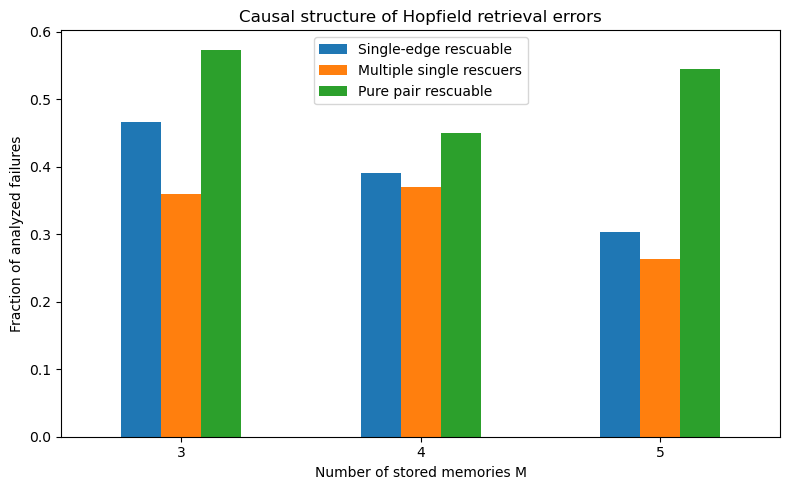

In [12]:
df = pd.DataFrame(
    all_results
)

df.to_csv(
    "hopfield_causal_robustness.csv",
    index=False
)

print(
    "Failure cases analyzed:",
    len(df)
)

summary = (
    df
    .groupby("M")
    .agg(
        failure_cases=(
            "failure_id",
            "count"
        ),

        mean_retrieval_accuracy=(
            "retrieval_accuracy",
            "mean"
        ),

        single_rescuable_fraction=(
            "has_single",
            "mean"
        ),

        redundant_single_fraction=(
            "has_multiple_single",
            "mean"
        ),

        pure_pair_fraction=(
            "has_pure_pair",
            "mean"
        ),

        mean_single_rescuers=(
            "n_single",
            "mean"
        )
    )
)

print(summary)

plot_df = (
    df
    .groupby("M")[
        [
            "has_single",
            "has_multiple_single",
            "has_pure_pair"
        ]
    ]
    .mean()
)

plot_df.plot(
    kind="bar",
    figsize=(8,5)
)

plt.ylabel(
    "Fraction of analyzed failures"
)

plt.xlabel(
    "Number of stored memories M"
)

plt.title(
    "Causal structure of Hopfield retrieval errors"
)

plt.xticks(
    rotation=0
)

plt.legend([
    "Single-edge rescuable",
    "Multiple single rescuers",
    "Pure pair rescuable"
])

plt.tight_layout()
plt.show()

In [13]:
def pattern_overlap_stats(patterns):

    M, N = patterns.shape

    C = (
        patterns
        @ patterns.T
    ) / N

    mask = ~torch.eye(
        M,
        dtype=torch.bool
    )

    off_diag = C[mask]

    return {
        "mean_abs_overlap":
            off_diag.abs().mean().item(),

        "rms_overlap":
            torch.sqrt(
                (off_diag ** 2).mean()
            ).item(),

        "max_abs_overlap":
            off_diag.abs().max().item()
    }

In [14]:
def sampled_corruptions(
    pattern,
    n_flips,
    n_samples,
    seed
):

    combos = list(
        itertools.combinations(
            range(len(pattern)),
            n_flips
        )
    )

    rng = random.Random(seed)

    if n_samples >= len(combos):
        selected = combos
    else:
        selected = rng.sample(
            combos,
            n_samples
        )

    rows = []

    for indices in selected:

        x = pattern.clone()

        for i in indices:
            x[i] *= -1

        rows.append(
            (indices, x)
        )

    return rows

In [15]:
def analyze_failure_order(
    x_fail,
    target,
    W
):

    edges = nonzero_edges(W)

    # =====================================
    # ORDER 1
    # =====================================

    single_rescuers = []

    for e in edges:

        W_do = remove_edges(
            W,
            [e]
        )

        out = hopfield_retrieve(
            x_fail,
            W_do
        )

        if torch.equal(
            out,
            target
        ):
            single_rescuers.append(e)

    if len(single_rescuers) > 0:

        return {
            "causal_order": 1,

            "n_single_rescuers":
                len(single_rescuers),

            "first_single":
                str(single_rescuers[0]),

            "first_pair":
                None
        }


    # =====================================
    # ORDER 2
    # =====================================

    for a in range(len(edges)):

        for b in range(
            a + 1,
            len(edges)
        ):

            e1 = edges[a]
            e2 = edges[b]

            W_do = remove_edges(
                W,
                [e1, e2]
            )

            out = hopfield_retrieve(
                x_fail,
                W_do
            )

            if torch.equal(
                out,
                target
            ):

                return {
                    "causal_order": 2,

                    "n_single_rescuers": 0,

                    "first_single": None,

                    "first_pair":
                        str((e1, e2))
                }


    # =====================================
    # NON RISOLTO FINO A ORDER 2
    # =====================================

    return {
        "causal_order": 3,
        # 3 significa >2, NON esattamente 3

        "n_single_rescuers": 0,

        "first_single": None,

        "first_pair": None
    }

In [16]:
def run_load_experiment(
    N,
    M,
    corruption_fraction,
    seed,
    corruption_samples=100,
    max_failures_per_target=4
):

    patterns = random_patterns(
        N,
        M,
        seed
    )

    W = hebbian_weights(
        patterns
    )

    overlap_stats = (
        pattern_overlap_stats(
            patterns
        )
    )

    n_flips = max(
        1,
        round(
            corruption_fraction * N
        )
    )

    rows = []

    for target_id in range(M):

        target = patterns[
            target_id
        ]

        corruptions = sampled_corruptions(
            target,
            n_flips,
            corruption_samples,
            seed=(
                seed * 10000
                + target_id
            )
        )

        failures = []

        correct = 0

        for indices, x in corruptions:

            out = hopfield_retrieve(
                x,
                W
            )

            if torch.equal(
                out,
                target
            ):
                correct += 1

            else:
                failures.append(
                    (indices, x)
                )

        accuracy = (
            correct
            / len(corruptions)
        )

        # failure subset riproducibile
        rng = random.Random(
            seed * 100000
            + target_id
        )

        rng.shuffle(failures)

        selected_failures = (
            failures[
                :max_failures_per_target
            ]
        )

        for failure_id, (
            indices,
            x_fail
        ) in enumerate(
            selected_failures
        ):

            causal = (
                analyze_failure_order(
                    x_fail,
                    target,
                    W
                )
            )

            rows.append({

                "N": N,
                "M": M,

                "alpha_actual":
                    M / N,

                "seed": seed,

                "target_id":
                    target_id,

                "failure_id":
                    failure_id,

                "n_flips":
                    n_flips,

                "retrieval_accuracy":
                    accuracy,

                "n_failures_sample":
                    len(failures),

                "mean_abs_overlap":
                    overlap_stats[
                        "mean_abs_overlap"
                    ],

                "rms_overlap":
                    overlap_stats[
                        "rms_overlap"
                    ],

                "max_abs_overlap":
                    overlap_stats[
                        "max_abs_overlap"
                    ],

                "flipped_bits":
                    str(indices),

                **causal
            })

    return rows

In [17]:
N_values = [
    12,
    16,
    20
]

alpha_values = [
    0.10,
    0.20,
    0.30,
    0.40
]

corruption_fraction = 0.25

n_seeds = 5

In [18]:
all_rows = []

for N in N_values:

    for alpha in alpha_values:

        M = max(
            2,
            round(alpha * N)
        )

        for seed in range(n_seeds):

            print(
                f"N={N} | "
                f"M={M} | "
                f"alpha={M/N:.3f} | "
                f"seed={seed}"
            )

            rows = run_load_experiment(
                N=N,
                M=M,
                corruption_fraction=
                    corruption_fraction,
                seed=seed,
                corruption_samples=100,
                max_failures_per_target=4
            )

            all_rows.extend(rows)

            # Salvataggio progressivo
            pd.DataFrame(
                all_rows
            ).to_csv(
                "hopfield_load_results.csv",
                index=False
            )

N=12 | M=2 | alpha=0.167 | seed=0
N=12 | M=2 | alpha=0.167 | seed=1
N=12 | M=2 | alpha=0.167 | seed=2
N=12 | M=2 | alpha=0.167 | seed=3
N=12 | M=2 | alpha=0.167 | seed=4
N=12 | M=2 | alpha=0.167 | seed=0
N=12 | M=2 | alpha=0.167 | seed=1
N=12 | M=2 | alpha=0.167 | seed=2
N=12 | M=2 | alpha=0.167 | seed=3
N=12 | M=2 | alpha=0.167 | seed=4
N=12 | M=4 | alpha=0.333 | seed=0
N=12 | M=4 | alpha=0.333 | seed=1
N=12 | M=4 | alpha=0.333 | seed=2
N=12 | M=4 | alpha=0.333 | seed=3
N=12 | M=4 | alpha=0.333 | seed=4
N=12 | M=5 | alpha=0.417 | seed=0
N=12 | M=5 | alpha=0.417 | seed=1
N=12 | M=5 | alpha=0.417 | seed=2
N=12 | M=5 | alpha=0.417 | seed=3
N=12 | M=5 | alpha=0.417 | seed=4
N=16 | M=2 | alpha=0.125 | seed=0
N=16 | M=2 | alpha=0.125 | seed=1
N=16 | M=2 | alpha=0.125 | seed=2
N=16 | M=2 | alpha=0.125 | seed=3
N=16 | M=2 | alpha=0.125 | seed=4
N=16 | M=3 | alpha=0.188 | seed=0
N=16 | M=3 | alpha=0.188 | seed=1
N=16 | M=3 | alpha=0.188 | seed=2
N=16 | M=3 | alpha=0.188 | seed=3
N=16 | M=3 | a

In [21]:
df = pd.DataFrame(
    all_rows
)

df["order1"] = (
    df["causal_order"] == 1
).astype(float)

df["order2"] = (
    df["causal_order"] == 2
).astype(float)

df["order_gt2"] = (
    df["causal_order"] == 3
).astype(float)

In [22]:
summary = (
    df
    .groupby(
        ["N", "M", "alpha_actual"]
    )
    .agg(

        analyzed_failures=(
            "failure_id",
            "count"
        ),

        retrieval_accuracy=(
            "retrieval_accuracy",
            "mean"
        ),

        mean_abs_overlap=(
            "mean_abs_overlap",
            "mean"
        ),

        order1_fraction=(
            "order1",
            "mean"
        ),

        order2_fraction=(
            "order2",
            "mean"
        ),

        order_gt2_fraction=(
            "order_gt2",
            "mean"
        )
    )
    .reset_index()
)

print(summary)

     N  M  alpha_actual  analyzed_failures  retrieval_accuracy  \
0   12  2      0.166667                 80            0.908000   
1   12  4      0.333333                 80            0.381000   
2   12  5      0.416667                100            0.219200   
3   16  2      0.125000                 31            0.909355   
4   16  3      0.187500                 60            0.542000   
5   16  5      0.312500                100            0.143200   
6   16  6      0.375000                120            0.081667   
7   20  2      0.100000                 18            0.971111   
8   20  4      0.200000                 80            0.618000   
9   20  6      0.300000                120            0.249333   
10  20  8      0.400000                160            0.092750   

    mean_abs_overlap  order1_fraction  order2_fraction  order_gt2_fraction  
0           0.166667         0.525000         0.350000            0.125000  
1           0.227778         0.387500         0.30000

In [23]:
causal_summary = (
    df
    .groupby(
        "alpha_actual"
    )[
        [
            "order1",
            "order2",
            "order_gt2"
        ]
    ]
    .mean()
    .reset_index()
)

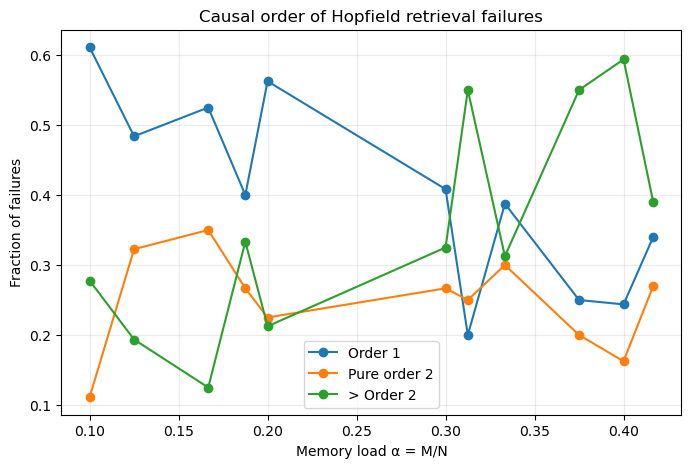

In [24]:
plt.figure(
    figsize=(8,5)
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order1"
    ],
    marker="o",
    label="Order 1"
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order2"
    ],
    marker="o",
    label="Pure order 2"
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order_gt2"
    ],
    marker="o",
    label="> Order 2"
)

plt.xlabel(
    "Memory load α = M/N"
)

plt.ylabel(
    "Fraction of failures"
)

plt.title(
    "Causal order of Hopfield retrieval failures"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()

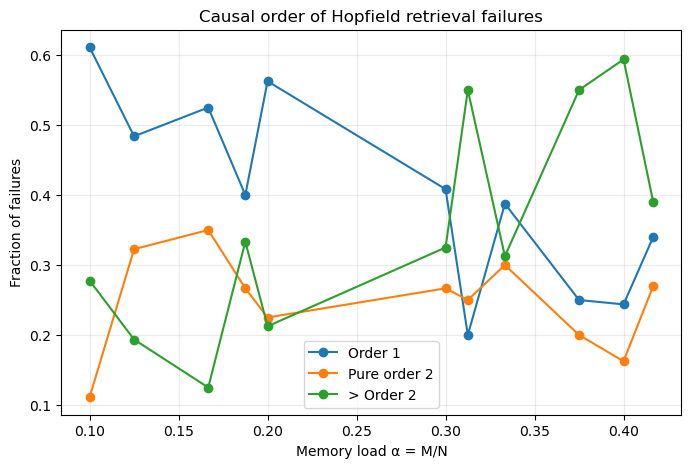

In [25]:
plt.figure(
    figsize=(8,5)
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order1"
    ],
    marker="o",
    label="Order 1"
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order2"
    ],
    marker="o",
    label="Pure order 2"
)

plt.plot(
    causal_summary[
        "alpha_actual"
    ],
    causal_summary[
        "order_gt2"
    ],
    marker="o",
    label="> Order 2"
)

plt.xlabel(
    "Memory load α = M/N"
)

plt.ylabel(
    "Fraction of failures"
)

plt.title(
    "Causal order of Hopfield retrieval failures"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()

In [26]:
corr = np.corrcoef(
    df["mean_abs_overlap"],
    df["causal_order"]
)[0,1]

print(
    "Correlation overlap / causal order:",
    corr
)

Correlation overlap / causal order: 0.12713780147341866


In [27]:
import pandas as pd
import numpy as np
import torch

df = pd.read_csv(
    "hopfield_load_results.csv"
)

print("Rows prima:", len(df))

identity_cols = [
    "N",
    "M",
    "seed",
    "target_id",
    "failure_id",
    "flipped_bits"
]

df = (
    df
    .drop_duplicates(
        subset=identity_cols
    )
    .reset_index(drop=True)
)

print("Rows dopo:", len(df))

Rows prima: 949
Rows dopo: 909


In [28]:
def cross_talk_stats(patterns):

    M, N = patterns.shape

    C = (
        patterns
        @ patterns.T
    ) / N

    C = C.clone()

    C.fill_diagonal_(0.0)

    # Cross-talk totale visto
    # da ogni pattern
    chi_per_pattern = torch.sqrt(
        torch.sum(
            C ** 2,
            dim=1
        )
    )

    off_diag_mask = ~torch.eye(
        M,
        dtype=torch.bool
    )

    off_diag = C[
        off_diag_mask
    ]

    return {
        "mean_abs_overlap":
            off_diag.abs().mean().item(),

        "rms_overlap":
            torch.sqrt(
                (off_diag ** 2).mean()
            ).item(),

        "cross_talk_strength":
            chi_per_pattern.mean().item(),

        "cross_talk_max":
            chi_per_pattern.max().item(),

        "cross_talk_theory":
            np.sqrt(
                (M - 1) / N
            )
    }

In [29]:
network_rows = []

unique_networks = (
    df[
        ["N", "M", "seed"]
    ]
    .drop_duplicates()
)

for row in unique_networks.itertuples(
    index=False
):

    N = int(row.N)
    M = int(row.M)
    seed = int(row.seed)

    patterns_tmp = random_patterns(
        N,
        M,
        seed
    )

    stats = cross_talk_stats(
        patterns_tmp
    )

    network_rows.append({
        "N": N,
        "M": M,
        "seed": seed,
        "alpha_actual": M / N,
        **stats
    })

network_stats = pd.DataFrame(
    network_rows
)

In [30]:
# Togliamo le vecchie metriche
# prima di fare il merge

cols_to_remove = [
    "mean_abs_overlap",
    "rms_overlap",
    "cross_talk_strength",
    "cross_talk_max",
    "cross_talk_theory"
]

df = df.drop(
    columns=[
        c for c in cols_to_remove
        if c in df.columns
    ]
)

df = df.merge(
    network_stats,
    on=["N", "M", "seed"],
    how="left"
)

df.to_csv(
    "hopfield_load_results_clean.csv",
    index=False
)

In [31]:
df["order1"] = (
    df["causal_order"] == 1
).astype(float)

df["order2"] = (
    df["causal_order"] == 2
).astype(float)

df["order_gt2"] = (
    df["causal_order"] == 3
).astype(float)

In [32]:
target_df = (
    df
    .drop_duplicates(
        subset=[
            "N",
            "M",
            "seed",
            "target_id"
        ]
    )
)

In [33]:
# Accuracy a livello rete
accuracy_network = (
    target_df
    .groupby(
        ["N", "M", "seed"]
    )
    .agg(
        retrieval_accuracy=(
            "retrieval_accuracy",
            "mean"
        )
    )
    .reset_index()
)

In [34]:
causal_network = (
    df
    .groupby(
        ["N", "M", "seed"]
    )
    .agg(
        analyzed_failures=(
            "failure_id",
            "count"
        ),

        order1_fraction=(
            "order1",
            "mean"
        ),

        order2_fraction=(
            "order2",
            "mean"
        ),

        order_gt2_fraction=(
            "order_gt2",
            "mean"
        )
    )
    .reset_index()
)

In [35]:
network_df = (
    accuracy_network
    .merge(
        causal_network,
        on=["N", "M", "seed"]
    )
    .merge(
        network_stats,
        on=["N", "M", "seed"]
    )
)

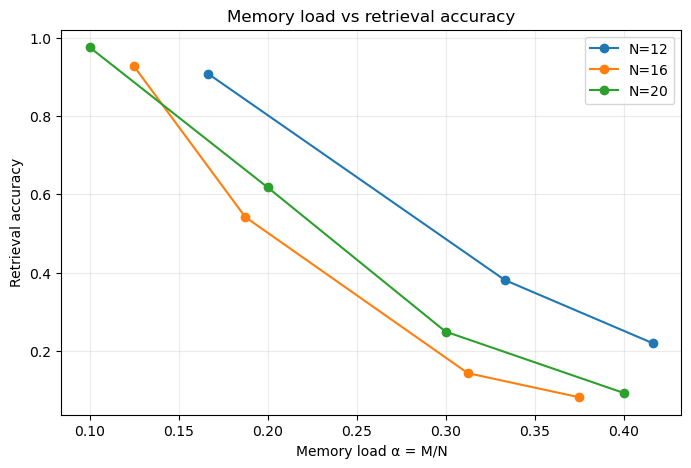

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for N in sorted(
    network_df["N"].unique()
):

    d = (
        network_df[
            network_df["N"] == N
        ]
        .groupby("alpha_actual")
        ["retrieval_accuracy"]
        .mean()
        .reset_index()
        .sort_values("alpha_actual")
    )

    plt.plot(
        d["alpha_actual"],
        d["retrieval_accuracy"],
        marker="o",
        label=f"N={N}"
    )

plt.xlabel(
    "Memory load α = M/N"
)

plt.ylabel(
    "Retrieval accuracy"
)

plt.title(
    "Memory load vs retrieval accuracy"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()

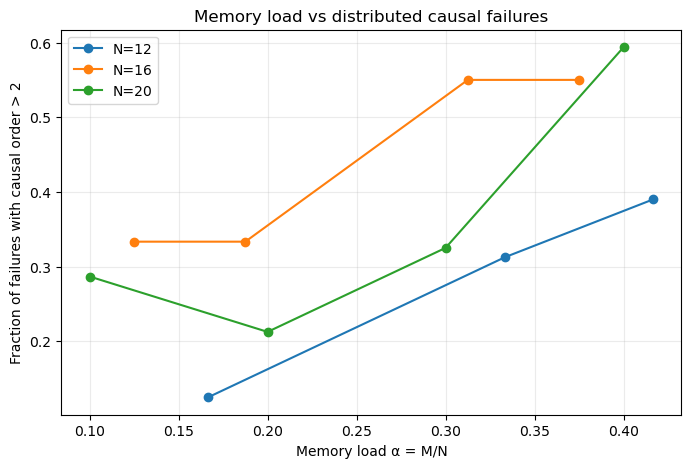

In [37]:
plt.figure(figsize=(8,5))

for N in sorted(
    network_df["N"].unique()
):

    d = (
        network_df[
            network_df["N"] == N
        ]
        .groupby("alpha_actual")
        ["order_gt2_fraction"]
        .mean()
        .reset_index()
        .sort_values("alpha_actual")
    )

    plt.plot(
        d["alpha_actual"],
        d["order_gt2_fraction"],
        marker="o",
        label=f"N={N}"
    )

plt.xlabel(
    "Memory load α = M/N"
)

plt.ylabel(
    "Fraction of failures with causal order > 2"
)

plt.title(
    "Memory load vs distributed causal failures"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()

In [38]:
print(
    "Spearman chi / accuracy:"
)

print(
    network_df[
        [
            "cross_talk_strength",
            "retrieval_accuracy"
        ]
    ]
    .corr(
        method="spearman"
    )
)

Spearman chi / accuracy:
                     cross_talk_strength  retrieval_accuracy
cross_talk_strength             1.000000           -0.869616
retrieval_accuracy             -0.869616            1.000000


In [39]:
print(
    "Spearman chi / order>2:"
)

print(
    network_df[
        [
            "cross_talk_strength",
            "order_gt2_fraction"
        ]
    ]
    .corr(
        method="spearman"
    )
)

Spearman chi / order>2:
                     cross_talk_strength  order_gt2_fraction
cross_talk_strength              1.00000             0.60886
order_gt2_fraction               0.60886             1.00000


In [40]:
def retrieve_one_state_many_W(
    x,
    W_batch,
    max_sweeps=20,
    tol=1e-12
):

    B, N, _ = W_batch.shape

    s = (
        x
        .unsqueeze(0)
        .expand(B, -1)
        .clone()
    )

    for _ in range(max_sweeps):

        changed = False

        for i in range(N):

            old = s[:, i].clone()

            field = torch.sum(
                W_batch[:, i, :]
                * s,
                dim=1
            )

            new = torch.where(
                field > tol,
                torch.ones_like(field),
                torch.where(
                    field < -tol,
                    -torch.ones_like(field),
                    old
                )
            )

            if torch.any(
                new != old
            ):
                changed = True

            s[:, i] = new

        if not changed:
            break

    return s

In [41]:
def find_first_pure_pair_fast(
    x_fail,
    target,
    W,
    edges,
    single_rescuers,
    chunk_size=2048
):

    single_set = set(
        single_rescuers
    )

    candidates = [
        e for e in edges
        if e not in single_set
    ]

    pairs = list(
        itertools.combinations(
            candidates,
            2
        )
    )

    for start in range(
        0,
        len(pairs),
        chunk_size
    ):

        chunk = pairs[
            start:start+chunk_size
        ]

        B = len(chunk)

        W_batch = (
            W
            .unsqueeze(0)
            .repeat(B, 1, 1)
        )

        rows = torch.arange(B)

        i1 = torch.tensor([
            p[0][0]
            for p in chunk
        ])

        j1 = torch.tensor([
            p[0][1]
            for p in chunk
        ])

        i2 = torch.tensor([
            p[1][0]
            for p in chunk
        ])

        j2 = torch.tensor([
            p[1][1]
            for p in chunk
        ])

        W_batch[
            rows, i1, j1
        ] = 0

        W_batch[
            rows, j1, i1
        ] = 0

        W_batch[
            rows, i2, j2
        ] = 0

        W_batch[
            rows, j2, i2
        ] = 0

        out = retrieve_one_state_many_W(
            x_fail,
            W_batch
        )

        hit = torch.all(
            out == target,
            dim=1
        )

        if hit.any():

            k = torch.where(
                hit
            )[0][0].item()

            return chunk[k]

    return None

In [42]:
for N in sorted(network_df["N"].unique()):

    d = network_df[
        network_df["N"] == N
    ]

    print(f"\nN = {N}")

    print(
        "chi vs accuracy:",
        d[
            [
                "cross_talk_strength",
                "retrieval_accuracy"
            ]
        ]
        .corr(method="spearman")
        .iloc[0,1]
    )

    print(
        "chi vs unresolved<=2:",
        d[
            [
                "cross_talk_strength",
                "order_gt2_fraction"
            ]
        ]
        .corr(method="spearman")
        .iloc[0,1]
    )


N = 12
chi vs accuracy: -0.8908779907877655
chi vs unresolved<=2: 0.7140333965355462

N = 16
chi vs accuracy: -0.8156510962125813
chi vs unresolved<=2: 0.5616758387088974

N = 20
chi vs accuracy: -0.878343310251582
chi vs unresolved<=2: 0.5137901119331946


In [44]:
import statsmodels.api as sm

X = network_df[
    [
        "alpha_actual",
        "cross_talk_strength"
    ]
].copy()

X["inv_N"] = (
    1.0 / network_df["N"]
)

X = sm.add_constant(X)

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7956fecdd7f0>>
Traceback (most recent call last):
  File "/home/davide/Downloads/ml_proj/env/lib/python3.13/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


In [ ]:
model_acc = sm.OLS(
    network_df["retrieval_accuracy"],
    X
).fit()

print(
    model_acc.summary()
)

In [ ]:
model_causal = sm.OLS(
    network_df["order_gt2_fraction"],
    X
).fit()

print(
    model_causal.summary()
)

In [45]:
import numpy as np

# Predittori:
# 1) alpha
# 2) cross-talk strength
# 3) 1/N
#
# aggiungiamo anche una colonna di 1 per l'intercetta

X = np.column_stack([
    np.ones(len(network_df)),
    network_df["alpha_actual"].values,
    network_df["cross_talk_strength"].values,
    1.0 / network_df["N"].values
])

In [46]:
y_acc = network_df[
    "retrieval_accuracy"
].values

beta_acc, *_ = np.linalg.lstsq(
    X,
    y_acc,
    rcond=None
)

print("ACCURACY")
print("intercept =", beta_acc[0])
print("alpha     =", beta_acc[1])
print("cross-talk=", beta_acc[2])
print("1/N       =", beta_acc[3])

ACCURACY
intercept = 1.0017028499057796
alpha     = -1.9202451579658586
cross-talk= -0.7208765028424056
1/N       = 4.167125908431235


In [47]:
y_causal = network_df[
    "order_gt2_fraction"
].values

beta_causal, *_ = np.linalg.lstsq(
    X,
    y_causal,
    rcond=None
)

print("\nUNRESOLVED <= 2")
print("intercept =", beta_causal[0])
print("alpha     =", beta_causal[1])
print("cross-talk=", beta_causal[2])
print("1/N       =", beta_causal[3])


UNRESOLVED <= 2
intercept = 0.33463092389717514
alpha     = 0.5508260000048588
cross-talk= 0.28721002035929005
1/N       = -3.641594759815511


In [48]:
for N in sorted(
    network_df["N"].unique()
):

    d = network_df[
        network_df["N"] == N
    ]

    print(f"\nN = {N}")

    print(
        "chi vs accuracy:",
        d[
            [
                "cross_talk_strength",
                "retrieval_accuracy"
            ]
        ]
        .corr(method="spearman")
        .iloc[0,1]
    )

    print(
        "chi vs unresolved<=2:",
        d[
            [
                "cross_talk_strength",
                "order_gt2_fraction"
            ]
        ]
        .corr(method="spearman")
        .iloc[0,1]
    )


N = 12
chi vs accuracy: -0.8908779907877655
chi vs unresolved<=2: 0.7140333965355462

N = 16
chi vs accuracy: -0.8156510962125813
chi vs unresolved<=2: 0.5616758387088974

N = 20
chi vs accuracy: -0.878343310251582
chi vs unresolved<=2: 0.5137901119331946


In [49]:
def batch_trace_states(
    initial_states,
    W,
    max_sweeps=20,
    tol=1e-12
):
    s = initial_states.clone()

    traces = [s.clone()]

    for _ in range(max_sweeps):

        changed = False

        for i in range(s.shape[1]):

            old = s[:, i].clone()

            field = torch.sum(
                s * W[i].unsqueeze(0),
                dim=1
            )

            new = torch.where(
                field > tol,
                torch.ones_like(field),
                torch.where(
                    field < -tol,
                    -torch.ones_like(field),
                    old
                )
            )

            if torch.any(new != old):
                changed = True

            s[:, i] = new

        traces.append(s.clone())

        if not changed:
            break

    return torch.stack(traces)

In [50]:
def retrieve_one_state_many_W(
    x,
    W_batch,
    max_sweeps=20,
    tol=1e-12
):
    B, N, _ = W_batch.shape

    s = (
        x.unsqueeze(0)
        .expand(B, -1)
        .clone()
    )

    for _ in range(max_sweeps):

        changed = False

        for i in range(N):

            old = s[:, i].clone()

            field = torch.sum(
                W_batch[:, i, :] * s,
                dim=1
            )

            new = torch.where(
                field > tol,
                torch.ones_like(field),
                torch.where(
                    field < -tol,
                    -torch.ones_like(field),
                    old
                )
            )

            if torch.any(new != old):
                changed = True

            s[:, i] = new

        if not changed:
            break

    return s

In [51]:
def analyze_failure_order_fast(
    x_fail,
    target,
    W,
    chunk_size=4096
):
    edges = nonzero_edges(W)

    # ==========================================
    # ORDER 1
    # ==========================================

    B = len(edges)

    W_batch = (
        W.unsqueeze(0)
        .repeat(B, 1, 1)
    )

    rows = torch.arange(B)

    ii = torch.tensor(
        [e[0] for e in edges],
        dtype=torch.long
    )

    jj = torch.tensor(
        [e[1] for e in edges],
        dtype=torch.long
    )

    W_batch[rows, ii, jj] = 0.0
    W_batch[rows, jj, ii] = 0.0

    outs = retrieve_one_state_many_W(
        x_fail,
        W_batch
    )

    hit = torch.all(
        outs == target,
        dim=1
    )

    single_ids = torch.where(hit)[0].tolist()

    single_rescuers = [
        edges[k]
        for k in single_ids
    ]

    if single_rescuers:

        return {
            "causal_class": "order1",
            "n_single_rescuers":
                len(single_rescuers),
            "first_single":
                str(single_rescuers[0]),
            "first_pair": None
        }

    # ==========================================
    # PURE ORDER 2
    # ==========================================

    pair_iterator = itertools.combinations(
        edges,
        2
    )

    while True:

        chunk = list(
            itertools.islice(
                pair_iterator,
                chunk_size
            )
        )

        if not chunk:
            break

        B = len(chunk)

        W_batch = (
            W.unsqueeze(0)
            .repeat(B, 1, 1)
        )

        rows = torch.arange(B)

        i1 = torch.tensor(
            [p[0][0] for p in chunk]
        )

        j1 = torch.tensor(
            [p[0][1] for p in chunk]
        )

        i2 = torch.tensor(
            [p[1][0] for p in chunk]
        )

        j2 = torch.tensor(
            [p[1][1] for p in chunk]
        )

        W_batch[rows, i1, j1] = 0
        W_batch[rows, j1, i1] = 0

        W_batch[rows, i2, j2] = 0
        W_batch[rows, j2, i2] = 0

        outs = retrieve_one_state_many_W(
            x_fail,
            W_batch
        )

        hit = torch.all(
            outs == target,
            dim=1
        )

        if hit.any():

            k = torch.where(
                hit
            )[0][0].item()

            return {
                "causal_class": "order2",
                "n_single_rescuers": 0,
                "first_single": None,
                "first_pair":
                    str(chunk[k])
            }

    return {
        "causal_class": "unresolved_le2",
        "n_single_rescuers": 0,
        "first_single": None,
        "first_pair": None
    }

In [52]:
def run_network_1c(
    N,
    M,
    seed,
    corruption_fraction=0.25,
    corruption_samples=100,
    max_failures_per_target=4
):
    patterns = random_patterns(
        N, M, seed
    )

    W = hebbian_weights(patterns)

    ct = cross_talk_stats(patterns)

    n_flips = max(
        1,
        round(
            corruption_fraction * N
        )
    )

    target_rows = []
    failure_rows = []

    for target_id in range(M):

        target = patterns[target_id]

        corruptions = sampled_corruptions(
            target,
            n_flips,
            corruption_samples,
            seed=seed * 10000 + target_id
        )

        X = torch.stack(
            [x for _, x in corruptions]
        )

        final_states = batch_trace_states(
            X,
            W
        )[-1]

        correct_mask = torch.all(
            final_states
            == target.unsqueeze(0),
            dim=1
        )

        accuracy = (
            correct_mask.float()
            .mean()
            .item()
        )

        # Questa riga viene salvata
        # anche se accuracy = 1
        target_rows.append({
            "N": N,
            "M": M,
            "alpha_actual": M / N,
            "seed": seed,
            "target_id": target_id,
            "retrieval_accuracy":
                accuracy,
            **ct
        })

        failure_ids = torch.where(
            ~correct_mask
        )[0].tolist()

        rng = random.Random(
            seed * 100000
            + target_id
        )

        rng.shuffle(failure_ids)

        selected = failure_ids[
            :max_failures_per_target
        ]

        for failure_id in selected:

            indices, x_fail = (
                corruptions[failure_id]
            )

            causal = (
                analyze_failure_order_fast(
                    x_fail,
                    target,
                    W
                )
            )

            failure_rows.append({
                "N": N,
                "M": M,
                "alpha_actual": M / N,
                "seed": seed,
                "target_id": target_id,
                "failure_id":
                    failure_id,
                "flipped_bits":
                    str(indices),
                **ct,
                **causal
            })

    return (
        target_rows,
        failure_rows
    )

In [53]:
from pathlib import Path

TARGET_FILE = Path(
    "phase1c_targets.csv"
)

FAILURE_FILE = Path(
    "phase1c_failures.csv"
)

DONE_FILE = Path(
    "phase1c_done.txt"
)

done = set()

if DONE_FILE.exists():

    for line in DONE_FILE.read_text().splitlines():

        M, seed = line.split(",")

        done.add(
            (int(M), int(seed))
        )


N = 20

M_values = [
    2, 4, 6, 8
]


for M in M_values:

    for seed in range(20):

        key = (M, seed)

        if key in done:

            print(
                "SKIP",
                key
            )

            continue

        print(
            f"N={N} | "
            f"M={M} | "
            f"alpha={M/N:.2f} | "
            f"seed={seed}"
        )

        target_rows, failure_rows = (
            run_network_1c(
                N=N,
                M=M,
                seed=seed,
                corruption_samples=100,
                max_failures_per_target=4
            )
        )

        new_targets = pd.DataFrame(
            target_rows
        )

        new_failures = pd.DataFrame(
            failure_rows
        )

        new_targets.to_csv(
            TARGET_FILE,
            mode="a",
            header=not TARGET_FILE.exists(),
            index=False
        )

        if len(new_failures) > 0:

            new_failures.to_csv(
                FAILURE_FILE,
                mode="a",
                header=not FAILURE_FILE.exists(),
                index=False
            )

        with open(
            DONE_FILE,
            "a"
        ) as f:

            f.write(
                f"{M},{seed}\n"
            )

N=20 | M=2 | alpha=0.10 | seed=0
N=20 | M=2 | alpha=0.10 | seed=1
N=20 | M=2 | alpha=0.10 | seed=2
N=20 | M=2 | alpha=0.10 | seed=3
N=20 | M=2 | alpha=0.10 | seed=4
N=20 | M=2 | alpha=0.10 | seed=5
N=20 | M=2 | alpha=0.10 | seed=6
N=20 | M=2 | alpha=0.10 | seed=7
N=20 | M=2 | alpha=0.10 | seed=8
N=20 | M=2 | alpha=0.10 | seed=9
N=20 | M=2 | alpha=0.10 | seed=10
N=20 | M=2 | alpha=0.10 | seed=11
N=20 | M=2 | alpha=0.10 | seed=12
N=20 | M=2 | alpha=0.10 | seed=13
N=20 | M=2 | alpha=0.10 | seed=14
N=20 | M=2 | alpha=0.10 | seed=15
N=20 | M=2 | alpha=0.10 | seed=16
N=20 | M=2 | alpha=0.10 | seed=17
N=20 | M=2 | alpha=0.10 | seed=18
N=20 | M=2 | alpha=0.10 | seed=19
N=20 | M=4 | alpha=0.20 | seed=0
N=20 | M=4 | alpha=0.20 | seed=1
N=20 | M=4 | alpha=0.20 | seed=2
N=20 | M=4 | alpha=0.20 | seed=3
N=20 | M=4 | alpha=0.20 | seed=4
N=20 | M=4 | alpha=0.20 | seed=5
N=20 | M=4 | alpha=0.20 | seed=6
N=20 | M=4 | alpha=0.20 | seed=7
N=20 | M=4 | alpha=0.20 | seed=8
N=20 | M=4 | alpha=0.20 | seed=9


In [54]:
targets_1c = pd.read_csv(
    "phase1c_targets.csv"
)

failures_1c = pd.read_csv(
    "phase1c_failures.csv"
)

In [55]:
network_acc = (
    targets_1c
    .groupby(
        ["M", "seed"]
    )
    .agg(
        retrieval_accuracy=(
            "retrieval_accuracy",
            "mean"
        ),

        cross_talk_strength=(
            "cross_talk_strength",
            "first"
        )
    )
    .reset_index()
)

network_acc["alpha"] = (
    network_acc["M"] / 20
)

In [56]:
failures_1c["order1"] = (
    failures_1c[
        "causal_class"
    ] == "order1"
).astype(float)

failures_1c["order2"] = (
    failures_1c[
        "causal_class"
    ] == "order2"
).astype(float)

failures_1c["unresolved_le2"] = (
    failures_1c[
        "causal_class"
    ] == "unresolved_le2"
).astype(float)

In [57]:
network_causal = (
    failures_1c
    .groupby(
        ["M", "seed"]
    )
    .agg(
        order1_fraction=(
            "order1",
            "mean"
        ),

        order2_fraction=(
            "order2",
            "mean"
        ),

        unresolved_le2_fraction=(
            "unresolved_le2",
            "mean"
        ),

        analyzed_failures=(
            "failure_id",
            "count"
        )
    )
    .reset_index()
)

In [58]:
network_1c = network_acc.merge(
    network_causal,
    on=["M", "seed"],
    how="left"
)

In [59]:
print(
    "chi vs accuracy:"
)

print(
    network_1c[
        [
            "cross_talk_strength",
            "retrieval_accuracy"
        ]
    ]
    .corr(
        method="spearman"
    )
)

chi vs accuracy:
                     cross_talk_strength  retrieval_accuracy
cross_talk_strength             1.000000           -0.840486
retrieval_accuracy             -0.840486            1.000000


In [60]:
print(
    "\nchi vs unresolved <=2:"
)

print(
    network_1c[
        [
            "cross_talk_strength",
            "unresolved_le2_fraction"
        ]
    ]
    .dropna()
    .corr(
        method="spearman"
    )
)


chi vs unresolved <=2:
                         cross_talk_strength  unresolved_le2_fraction
cross_talk_strength                 1.000000                 0.536263
unresolved_le2_fraction             0.536263                 1.000000


# Fase 2: Introduciamo l'Information Theory

In [67]:
def discrete_mutual_information(
    true_labels,
    observed_labels
):
    true_labels = np.asarray(
        true_labels
    )

    observed_labels = np.asarray(
        observed_labels
    )

    true_values = np.unique(
        true_labels
    )

    obs_values = np.unique(
        observed_labels
    )

    N = len(true_labels)

    mi = 0.0

    for m in true_values:

        for s in obs_values:

            joint = np.mean(
                (true_labels == m)
                &
                (observed_labels == s)
            )

            if joint == 0:
                continue

            pm = np.mean(
                true_labels == m
            )

            ps = np.mean(
                observed_labels == s
            )

            mi += (
                joint
                * np.log2(
                    joint
                    / (pm * ps)
                )
            )

    return mi

In [68]:
def information_dynamics(
    patterns,
    W,
    n_flips,
    n_samples_per_target=200,
    seed=0,
    max_sweeps=6,
    intervention_edges=None
):
    M, N = patterns.shape

    W_use = W.clone()

    if intervention_edges is not None:

        for i, j in intervention_edges:

            W_use[i, j] = 0.0
            W_use[j, i] = 0.0

    inputs = []
    labels = []

    for mu in range(M):

        corruptions = sampled_corruptions(
            patterns[mu],
            n_flips,
            n_samples_per_target,
            seed=seed * 10000 + mu
        )

        for _, x in corruptions:

            inputs.append(x)
            labels.append(mu)

    X = torch.stack(inputs)

    labels = torch.tensor(
        labels,
        dtype=torch.long
    )

    trace = batch_trace_states(
        X,
        W_use,
        max_sweeps=max_sweeps
    )

    # Pad fino a max_sweeps
    while trace.shape[0] < (
        max_sweeps + 1
    ):

        trace = torch.cat(
            [
                trace,
                trace[-1:].clone()
            ],
            dim=0
        )

    rows = []

    H_memory = np.log2(M)

    for t in range(
        max_sweeps + 1
    ):

        states = trace[t]

        overlaps = (
            states
            @ patterns.T
        ) / N

        max_overlap = (
            overlaps
            .max(dim=1)
            .values
        )

        winners = (
            overlaps
            .argmax(dim=1)
        )

        # Se due memorie hanno esattamente
        # lo stesso overlap, non scegliamo
        # arbitrariamente la prima.
        ties = (
            torch.abs(
                overlaps
                - max_overlap.unsqueeze(1)
            )
            < 1e-12
        ).sum(dim=1) > 1

        observed = winners.clone()

        # -1 = ambiguous
        observed[ties] = -1

        mi = discrete_mutual_information(
            labels.numpy(),
            observed.numpy()
        )

        winner_accuracy = (
            observed == labels
        ).float().mean().item()

        target_overlap = overlaps[
            torch.arange(
                len(labels)
            ),
            labels
        ].mean().item()

        exact_retrieval = torch.all(
            states
            ==
            patterns[labels],
            dim=1
        ).float().mean().item()

        rows.append({
            "t": t,
            "MI_bits": mi,

            "normalized_MI":
                mi / H_memory,

            "winner_accuracy":
                winner_accuracy,

            "mean_target_overlap":
                target_overlap,

            "exact_retrieval_fraction":
                exact_retrieval,

            "ambiguous_fraction":
                ties.float()
                .mean()
                .item()
        })

    return pd.DataFrame(rows)

In [63]:
info_rows = []

N = 20

for M in [2,4,6,8]:

    for seed in range(5):

        print(
            f"INFO | M={M} | "
            f"seed={seed}"
        )

        patterns = random_patterns(
            N,
            M,
            seed
        )

        W = hebbian_weights(
            patterns
        )

        info = information_dynamics(
            patterns,
            W,
            n_flips=5,
            n_samples_per_target=200,
            seed=seed,
            max_sweeps=6
        )

        info["N"] = N
        info["M"] = M
        info["alpha"] = M / N
        info["seed"] = seed

        info_rows.append(info)


info_df = pd.concat(
    info_rows,
    ignore_index=True
)

info_df.to_csv(
    "phase2_information_dynamics.csv",
    index=False
)

INFO | M=2 | seed=0
INFO | M=2 | seed=1
INFO | M=2 | seed=2
INFO | M=2 | seed=3
INFO | M=2 | seed=4
INFO | M=4 | seed=0
INFO | M=4 | seed=1
INFO | M=4 | seed=2
INFO | M=4 | seed=3
INFO | M=4 | seed=4
INFO | M=6 | seed=0
INFO | M=6 | seed=1
INFO | M=6 | seed=2
INFO | M=6 | seed=3
INFO | M=6 | seed=4
INFO | M=8 | seed=0
INFO | M=8 | seed=1
INFO | M=8 | seed=2
INFO | M=8 | seed=3
INFO | M=8 | seed=4


In [71]:
# Grafico principale della rete 2
info_summary = (
    info_df
    .groupby(
        ["alpha", "t"]
    )
    .agg(
        normalized_MI=(
            "normalized_MI",
            "mean"
        ),

        exact_accuracy=(
            "exact_retrieval_fraction",
            "mean"
        ),

        target_overlap=(
            "mean_target_overlap",
            "mean"
        )
    )
    .reset_index()
)

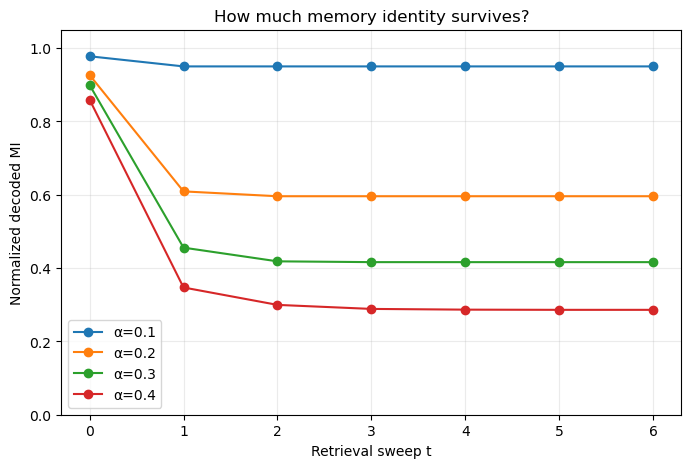

In [72]:
plt.figure(figsize=(8,5))

for alpha in sorted(
    info_summary[
        "alpha"
    ].unique()
):

    d = info_summary[
        info_summary[
            "alpha"
        ] == alpha
    ]

    plt.plot(
        d["t"],
        d["normalized_MI"],
        marker="o",
        label=f"α={alpha:.1f}"
    )

plt.xlabel(
    "Retrieval sweep t"
)

plt.ylabel(
    "Normalized decoded MI"
)

plt.title(
    "How much memory identity survives?"
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.show()

In [73]:
info_loss = (
    info_df
    .pivot_table(
        index=["M", "seed", "alpha"],
        columns="t",
        values="normalized_MI"
    )
    .reset_index()
)

info_loss["D1"] = (
    info_loss[0]
    - info_loss[1]
)

info_loss["D_total"] = (
    info_loss[0]
    - info_loss[6]
)

In [74]:
phase2b = network_1c.merge(
    info_loss[
        [
            "M",
            "seed",
            "D1",
            "D_total"
        ]
    ],
    on=[
        "M",
        "seed"
    ],
    how="inner"
)

In [75]:
print(
    phase2b[
        [
            "cross_talk_strength",
            "D1"
        ]
    ]
    .corr(
        method="spearman"
    )
)

                     cross_talk_strength        D1
cross_talk_strength             1.000000  0.733435
D1                              0.733435  1.000000


In [76]:
print(
    phase2b[
        [
            "D1",
            "retrieval_accuracy"
        ]
    ]
    .corr(
        method="spearman"
    )
)

                          D1  retrieval_accuracy
D1                  1.000000           -0.899248
retrieval_accuracy -0.899248            1.000000


In [77]:
print(
    phase2b[
        [
            "D1",
            "unresolved_le2_fraction"
        ]
    ]
    .dropna()
    .corr(
        method="spearman"
    )
)

                               D1  unresolved_le2_fraction
D1                       1.000000                 0.409681
unresolved_le2_fraction  0.409681                 1.000000


In [78]:
def zscore(x):
    x = np.asarray(x, dtype=float)
    return (
        x - x.mean()
    ) / x.std(ddof=0)


reg = phase2b.dropna(
    subset=[
        "alpha",
        "cross_talk_strength",
        "D1",
        "retrieval_accuracy",
        "unresolved_le2_fraction"
    ]
).copy()


X = np.column_stack([
    np.ones(len(reg)),
    zscore(reg["alpha"]),
    zscore(reg["cross_talk_strength"]),
    zscore(reg["D1"])
])

In [80]:
y = zscore(
    reg["retrieval_accuracy"]
)

beta_acc, *_ = np.linalg.lstsq(
    X,
    y,
    rcond=None
)

print(
    "ACCURACY standardized"
)

print("alpha =", beta_acc[1])
print("chi   =", beta_acc[2])
print("D1    =", beta_acc[3])

ACCURACY standardized
alpha = -0.565205890018048
chi   = -0.1786112896209841
D1    = -0.2592864889407627


In [79]:
y = zscore(
    reg["unresolved_le2_fraction"]
)

beta_complexity, *_ = np.linalg.lstsq(
    X,
    y,
    rcond=None
)

print(
    "\nUNRESOLVED <=2 standardized"
)

print("alpha =", beta_complexity[1])
print("chi   =", beta_complexity[2])
print("D1    =", beta_complexity[3])


UNRESOLVED <=2 standardized
alpha = 1.1448954975551624
chi   = 0.7137346049055509
D1    = -1.2998912663680624


In [81]:
print(
    reg[
        [
            "alpha",
            "cross_talk_strength",
            "D1"
        ]
    ].corr(method="spearman")
)

                        alpha  cross_talk_strength        D1
alpha                1.000000             0.862177  0.946191
cross_talk_strength  0.862177             1.000000  0.733435
D1                   0.946191             0.733435  1.000000


In [82]:
def vif_numpy(df, columns):

    result = {}

    for target_col in columns:

        other_cols = [
            c for c in columns
            if c != target_col
        ]

        y = zscore(
            df[target_col].values
        )

        X_other = np.column_stack([
            np.ones(len(df))
        ] + [
            zscore(
                df[c].values
            )
            for c in other_cols
        ])

        beta, *_ = np.linalg.lstsq(
            X_other,
            y,
            rcond=None
        )

        pred = X_other @ beta

        ss_res = np.sum(
            (y - pred) ** 2
        )

        ss_tot = np.sum(
            (y - y.mean()) ** 2
        )

        R2 = 1 - ss_res / ss_tot

        vif = 1 / (1 - R2)

        result[target_col] = {
            "R2": R2,
            "VIF": vif
        }

    return result


print(
    vif_numpy(
        reg,
        [
            "alpha",
            "cross_talk_strength",
            "D1"
        ]
    )
)

{'alpha': {'R2': np.float64(0.8935449200123396), 'VIF': np.float64(9.393633447233464)}, 'cross_talk_strength': {'R2': np.float64(0.8372600042905431), 'VIF': np.float64(6.144770962052384)}, 'D1': {'R2': np.float64(0.912837670596981), 'VIF': np.float64(11.472846203733548)}}


In [83]:
X2 = np.column_stack([
    np.ones(len(reg)),
    zscore(
        reg["cross_talk_strength"]
    ),
    zscore(
        reg["D1"]
    )
])

In [84]:
y = zscore(
    reg["retrieval_accuracy"]
)

beta, *_ = np.linalg.lstsq(
    X2,
    y,
    rcond=None
)

print(
    "ACCURACY | chi, D1"
)

print("chi =", beta[1])
print("D1  =", beta[2])

ACCURACY | chi, D1
chi = -0.28234404409939184
D1  = -0.6974155871348656


In [85]:
y = zscore(
    reg["unresolved_le2_fraction"]
)

beta, *_ = np.linalg.lstsq(
    X2,
    y,
    rcond=None
)

print(
    "\nUNRESOLVED <=2 | chi, D1"
)

print("chi =", beta[1])
print("D1  =", beta[2])


UNRESOLVED <=2 | chi, D1
chi = 0.9238583237994542
D1  = -0.4124057664304939


Quando un intervento su un edge corregge un errore, recupera anche informazione sulla memoria?

Definiamo:

$$ \Delta A_e = A^{do(e=0)}-A $$

e

$$ \boxed{ \Delta I_e = I_{\rm dec}^{do(e=0)}(M;S_1) - I_{\rm dec}(M;S_1). } $$

Se troviamo:

$$ \Delta A_e>0 \quad\text{e}\quad \Delta I_e>0, $$

l'intervento ha sia un behavioral rescue sia un information rescue.

In [86]:
N = 20
M = 6
seed = 0

patterns = random_patterns(
    N,
    M,
    seed
)

W = hebbian_weights(patterns)

n_flips = 5

In [87]:
inputs = []
labels = []

for mu in range(M):

    corruptions = sampled_corruptions(
        patterns[mu],
        n_flips,
        200,
        seed=10000 * seed + mu
    )

    for _, x in corruptions:
        inputs.append(x)
        labels.append(mu)

X_eval = torch.stack(inputs)

labels_eval = torch.tensor(
    labels,
    dtype=torch.long
)

In [88]:
def evaluate_information_behavior(
    X,
    labels,
    patterns,
    W,
    max_sweeps=6
):

    trace = batch_trace_states(
        X,
        W,
        max_sweeps=max_sweeps
    )

    rows = []

    M, N = patterns.shape
    H_M = np.log2(M)

    for t in range(trace.shape[0]):

        states = trace[t]

        overlaps = (
            states @ patterns.T
        ) / N

        max_values = (
            overlaps.max(dim=1).values
        )

        winners = (
            overlaps.argmax(dim=1)
        )

        ties = (
            torch.abs(
                overlaps
                - max_values.unsqueeze(1)
            ) < 1e-12
        ).sum(dim=1) > 1

        observed = winners.clone()
        observed[ties] = -1

        mi = discrete_mutual_information(
            labels.numpy(),
            observed.numpy()
        )

        exact = torch.all(
            states
            ==
            patterns[labels],
            dim=1
        ).float().mean().item()

        rows.append({
            "t": t,
            "normalized_MI":
                mi / H_M,
            "accuracy": exact
        })

    return pd.DataFrame(rows)

In [89]:
baseline = evaluate_information_behavior(
    X_eval,
    labels_eval,
    patterns,
    W
)

print(baseline)

   t  normalized_MI  accuracy
0  0       0.893703  0.000000
1  1       0.463114  0.079167
2  2       0.423598  0.063333
3  3       0.420598  0.074167
4  4       0.420598  0.074167


In [90]:
edges = nonzero_edges(W)

intervention_rows = []

I1_base = baseline.loc[
    baseline["t"] == 1,
    "normalized_MI"
].iloc[0]

A_final_base = baseline[
    "accuracy"
].iloc[-1]

In [91]:
for e in edges:

    i, j = e

    W_do = W.clone()

    W_do[i,j] = 0.0
    W_do[j,i] = 0.0

    result = evaluate_information_behavior(
        X_eval,
        labels_eval,
        patterns,
        W_do
    )

    I1_do = result.loc[
        result["t"] == 1,
        "normalized_MI"
    ].iloc[0]

    A_final_do = result[
        "accuracy"
    ].iloc[-1]

    intervention_rows.append({
        "edge": str(e),

        "delta_I1":
            I1_do - I1_base,

        "delta_accuracy":
            A_final_do - A_final_base
    })

In [93]:
intervention_df = pd.DataFrame(
    intervention_rows
)
print(
    intervention_df
    .sort_values(
        "delta_accuracy",
        ascending=False
    )
    .head(15)
)

         edge  delta_I1  delta_accuracy
11    (0, 16)  0.000363        0.057500
25    (1, 16) -0.002714        0.054167
72    (6, 16) -0.001496        0.048333
84    (8, 11)  0.016931        0.042500
78    (7, 11) -0.001004        0.027500
99   (10, 11) -0.002657        0.027500
107  (11, 16) -0.000372        0.020833
30     (2, 7) -0.002641        0.006667
1      (0, 4) -0.010343        0.006667
6      (0, 9) -0.007662        0.006667
20     (1, 9) -0.003937        0.006667
67     (6, 9)  0.002369        0.005833
36     (3, 7)  0.003299        0.005833
33    (2, 14) -0.007687        0.005000
42     (4, 5)  0.000333        0.005000


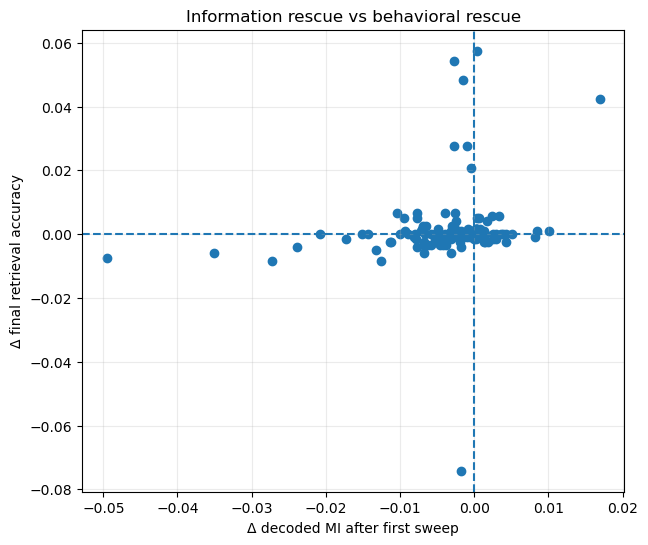

In [94]:
plt.figure(figsize=(7,6))

plt.scatter(
    intervention_df[
        "delta_I1"
    ],
    intervention_df[
        "delta_accuracy"
    ]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Δ decoded MI after first sweep"
)

plt.ylabel(
    "Δ final retrieval accuracy"
)

plt.title(
    "Information rescue vs behavioral rescue"
)

plt.grid(alpha=0.25)

plt.show()

In [95]:
print(
    intervention_df[
        [
            "delta_I1",
            "delta_accuracy"
        ]
    ]
    .corr(method="spearman")
)

                delta_I1  delta_accuracy
delta_I1        1.000000        0.267213
delta_accuracy  0.267213        1.000000


In [96]:
tmp = intervention_df.copy()

tmp["neutral_score"] = (
    tmp["delta_I1"].abs()
    + tmp["delta_accuracy"].abs()
)

neutral_edge_string = (
    tmp
    .sort_values("neutral_score")
    .iloc[0]["edge"]
)

print("Neutral edge:", neutral_edge_string)

Neutral edge: (6, 17)


In [97]:
import ast

neutral_edge = ast.literal_eval(
    neutral_edge_string
)

edges_to_test = {
    "behavioral_0_16": (0, 16),
    "behavioral_1_16": (1, 16),
    "information_8_11": (8, 11),
    "neutral": neutral_edge
}

print(edges_to_test)

{'behavioral_0_16': (0, 16), 'behavioral_1_16': (1, 16), 'information_8_11': (8, 11), 'neutral': (6, 17)}


In [98]:
trajectory_results = {}

# baseline
trajectory_results["baseline"] = (
    evaluate_information_behavior(
        X_eval,
        labels_eval,
        patterns,
        W,
        max_sweeps=6
    )
)

# interventi
for name, (i, j) in edges_to_test.items():

    W_do = W.clone()

    W_do[i, j] = 0.0
    W_do[j, i] = 0.0

    result = evaluate_information_behavior(
        X_eval,
        labels_eval,
        patterns,
        W_do,
        max_sweeps=6
    )

    trajectory_results[name] = result

In [99]:
rows = []

for name, result in trajectory_results.items():

    for _, row in result.iterrows():

        rows.append({
            "condition": name,
            "t": int(row["t"]),
            "normalized_MI":
                row["normalized_MI"],
            "accuracy":
                row["accuracy"]
        })

dynamic_df = pd.DataFrame(rows)

In [100]:
dynamic_df.to_csv(
    "phase2_dynamic_repairs.csv",
    index=False
)

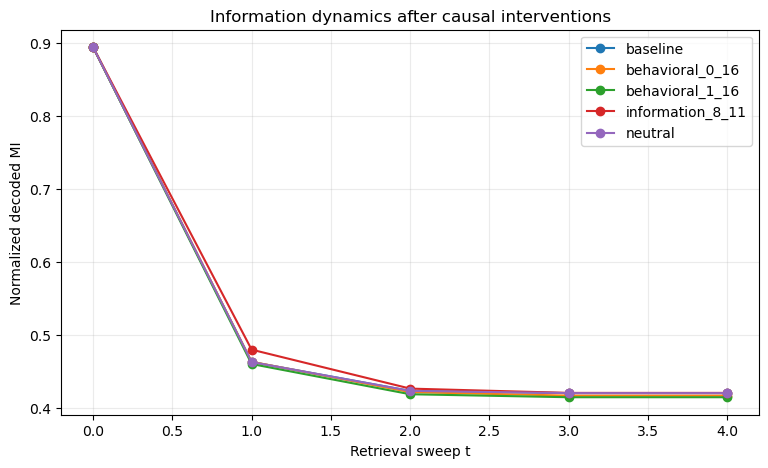

In [101]:
plt.figure(figsize=(9, 5))

for condition in dynamic_df[
    "condition"
].unique():

    d = dynamic_df[
        dynamic_df["condition"] == condition
    ]

    plt.plot(
        d["t"],
        d["normalized_MI"],
        marker="o",
        label=condition
    )

plt.xlabel("Retrieval sweep t")
plt.ylabel("Normalized decoded MI")

plt.title(
    "Information dynamics after causal interventions"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()

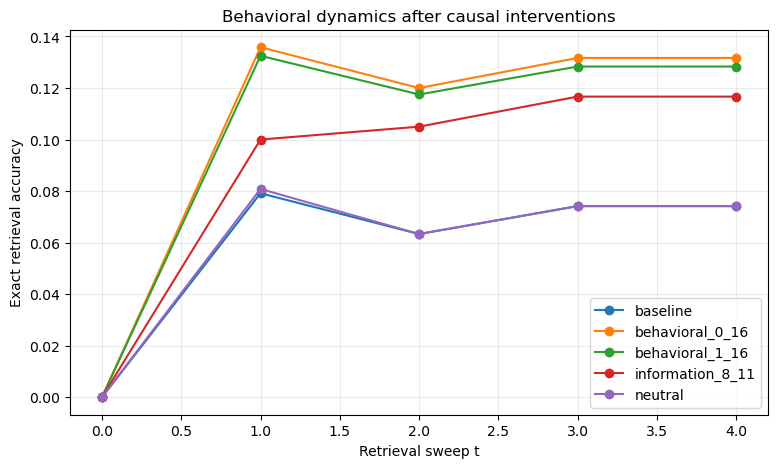

In [102]:
plt.figure(figsize=(9, 5))

for condition in dynamic_df[
    "condition"
].unique():

    d = dynamic_df[
        dynamic_df["condition"] == condition
    ]

    plt.plot(
        d["t"],
        d["accuracy"],
        marker="o",
        label=condition
    )

plt.xlabel("Retrieval sweep t")
plt.ylabel("Exact retrieval accuracy")

plt.title(
    "Behavioral dynamics after causal interventions"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()

In [103]:
base = trajectory_results[
    "baseline"
].set_index("t")

delta_rows = []

for name, result in trajectory_results.items():

    if name == "baseline":
        continue

    r = result.set_index("t")

    common_t = (
        base.index
        .intersection(r.index)
    )

    for t in common_t:

        delta_rows.append({
            "condition": name,
            "t": t,

            "delta_MI":
                r.loc[t, "normalized_MI"]
                -
                base.loc[t, "normalized_MI"],

            "delta_accuracy":
                r.loc[t, "accuracy"]
                -
                base.loc[t, "accuracy"]
        })


delta_dynamic = pd.DataFrame(
    delta_rows
)

print(delta_dynamic)

           condition  t  delta_MI  delta_accuracy
0    behavioral_0_16  0  0.000000        0.000000
1    behavioral_0_16  1  0.000363        0.056667
2    behavioral_0_16  2 -0.001653        0.056667
3    behavioral_0_16  3 -0.003426        0.057500
4    behavioral_0_16  4 -0.003426        0.057500
5    behavioral_1_16  0  0.000000        0.000000
6    behavioral_1_16  1 -0.002714        0.053333
7    behavioral_1_16  2 -0.004560        0.054167
8    behavioral_1_16  3 -0.005629        0.054167
9    behavioral_1_16  4 -0.005629        0.054167
10  information_8_11  0  0.000000        0.000000
11  information_8_11  1  0.016931        0.020833
12  information_8_11  2  0.003160        0.041667
13  information_8_11  3  0.000281        0.042500
14  information_8_11  4  0.000281        0.042500
15           neutral  0  0.000000        0.000000
16           neutral  1  0.000000        0.001667
17           neutral  2  0.000000        0.000000
18           neutral  3  0.000000        0.000000


In [104]:
epsilon = 0.005

for condition in delta_dynamic[
    "condition"
].unique():

    d = delta_dynamic[
        delta_dynamic["condition"]
        == condition
    ]

    info_hits = d[
        d["delta_MI"] > epsilon
    ]

    behavior_hits = d[
        d["delta_accuracy"] > epsilon
    ]

    first_info = (
        int(info_hits.iloc[0]["t"])
        if len(info_hits) > 0
        else None
    )

    first_behavior = (
        int(behavior_hits.iloc[0]["t"])
        if len(behavior_hits) > 0
        else None
    )

    print(
        f"{condition:20s} | "
        f"first info repair = {first_info} | "
        f"first behavioral repair = {first_behavior}"
    )

behavioral_0_16      | first info repair = None | first behavioral repair = 1
behavioral_1_16      | first info repair = None | first behavioral repair = 1
information_8_11     | first info repair = 1 | first behavioral repair = 1
neutral              | first info repair = None | first behavioral repair = None


In [105]:
torch.save(
    {
        "patterns": patterns,
        "W": W,
        "X_eval": X_eval,
        "labels_eval": labels_eval
    },
    "phase2_reference_system.pt"
)

In [106]:
intervention_df.to_csv(
    "phase2_all_single_interventions.csv",
    index=False
)